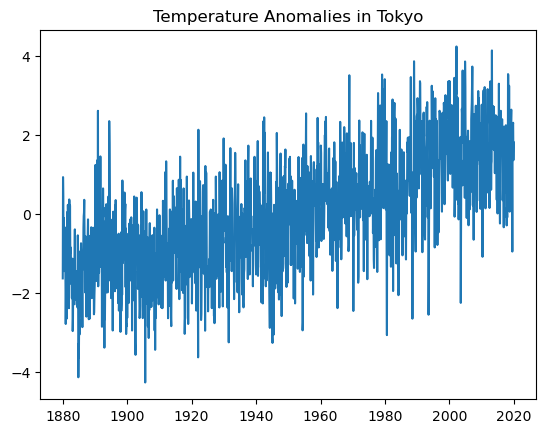

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

tokyo_temp = np.genfromtxt("Tokyo_temp.csv", 
                           delimiter=",",
                           usecols=(0, 1, 2)
                          )
y = tokyo_temp[:, 0]
m = tokyo_temp[:, 1]
temp = tokyo_temp[:, 2]

temp = temp[(1880 <= y)*(y <= 2019)]
m = m[(1880 <= y)*(y <= 2019)]
y = y[(1880 <= y)*(y <= 2019)]

temp_clim = np.zeros((12))
for mm in range(1, 13):
    temp_clim[mm-1] = np.nanmean(temp[m==mm], 0)

tempa = np.zeros((temp.shape))
for yy in range(1880, 2020):
    for mm in range(1, 13):
        tempa[(y==yy)*(m==mm)] = temp[(y==yy)*(m==mm)] - temp_clim[mm-1]

mon = np.arange(1880, 2020, 1/12)
plt.plot(mon, tempa)
plt.title('Temperature Anomalies in Tokyo')

plt.show()

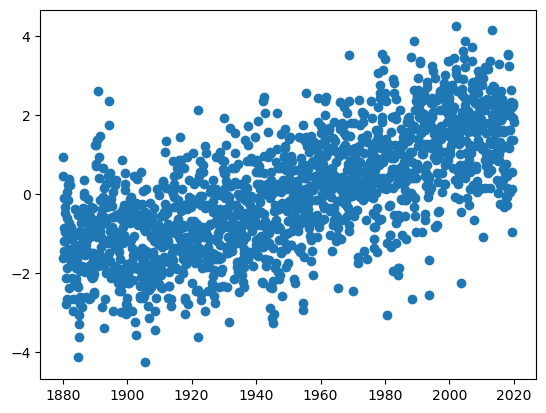

In [2]:
plt.scatter(mon,tempa)
plt.show()

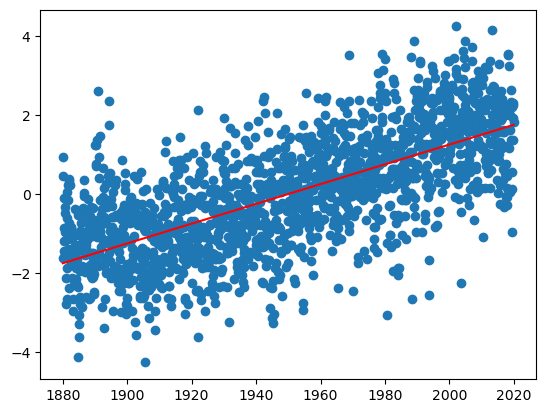

In [3]:
[a, b] = np.polyfit(mon, tempa, 1)
plt.scatter(mon, tempa)
plt.plot(mon, a*mon + b, 'r')
plt.show()

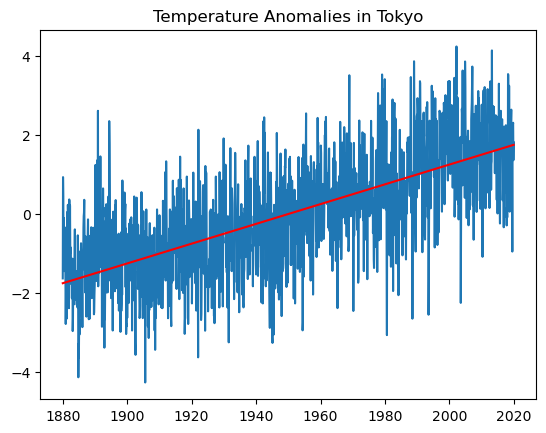

In [4]:
plt.plot(mon, tempa)
plt.plot(mon, a*mon + b, 'r')
plt.title('Temperature Anomalies in Tokyo')
plt.show()

In [5]:
a

np.float64(0.025054090509550334)

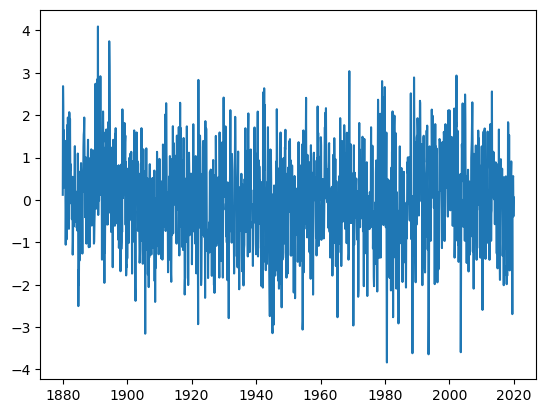

In [6]:
detrended_tempa = tempa - (a*mon + b)
plt.plot(mon,detrended_tempa)
plt.show()

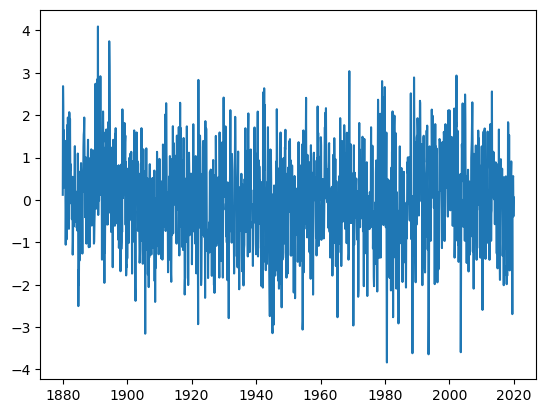

In [7]:
from scipy import signal

detrended_tempa_scipy = signal.detrend(tempa)
plt.plot(mon,detrended_tempa_scipy)
plt.show()

In [11]:
loadfile = 'ssta_OISST.npz'
ssta_dataset = np.load(loadfile)
ssta = ssta_dataset['ssta']
lon2 = ssta_dataset['lon2']
lat2 = ssta_dataset['lat2']
y = ssta_dataset['y']
m = ssta_dataset['m']

[imt, jmt, tmt] = ssta.shape

a_ssta = np.zeros((imt, jmt)) # 回归系数a
b_ssta = np.zeros((imt, jmt)) # 切片b
detrended_ssta = np.zeros((imt, jmt, tmt)) # 拉直之后的海面水温偏差

mon = np.arange(1982, 2020, 1/12)

is_land_grids_3D = (np.isnan(ssta)==True)
ssta[is_land_grids_3D] = 0

for ii in range(0, imt):
    for jj in range(0, jmt):
        [a_ssta[ii, jj], b_ssta[ii, jj]] = np.polyfit(mon, ssta[ii, jj, :], 1)
        detrended_ssta[ii, jj, :] = ssta[ii, jj, :] - (a_ssta[ii, jj]*mon + b_ssta[ii, jj])
    if (ii % 30 == 0):
        print(ii)

is_land_grids_2D = np.squeeze(is_land_grids_3D[:, :, 0])
a_ssta[is_land_grids_2D] = np.nan
b_ssta[is_land_grids_2D] = np.nan
detrended_ssta[is_land_grids_2D] = np.nan

0
30
60
90
120
150
180
210
240
270
300
330


In [12]:
savefile = 'detrended_ssta_OISST.npz'
np.savez(savefile, ssta=detrended_ssta, lon2=lon2, lat2=lat2, y=y, m=m)

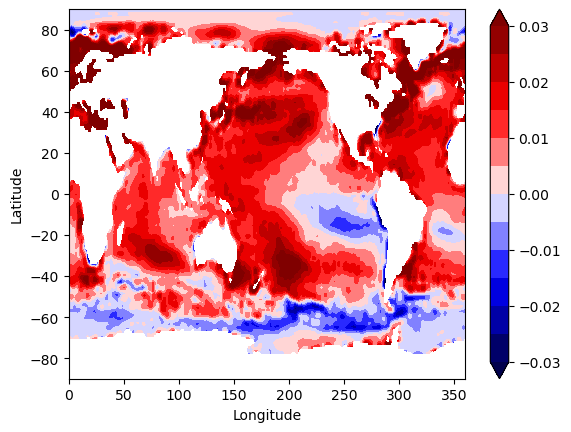

In [13]:
vmin = -0.03
vmax = 0.03
vint = 0.005

plt.figure()
cm = plt.get_cmap('seismic')
cs = plt.contourf(lon2, lat2, a_ssta, cmap=cm, norm=Normalize(vmin=vmin, vmax=vmax), levels=np.arange(vmin,vmax+vint,vint), extend='both')

plt.colorbar(cs)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
title = 'SST trend'
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.show()

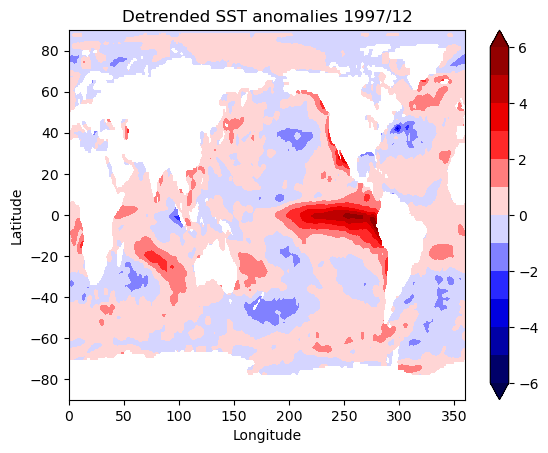

In [14]:
draw_year = 1997
draw_month = 12

vmin = -6
vmax = 6
vint = 1

plt.figure()
cm = plt.get_cmap('seismic')
cs = plt.contourf(lon2, lat2, np.squeeze(detrended_ssta[:,:,(y==draw_year)*(m==draw_month)]), cmap=cm, norm=Normalize(vmin=vmin,vmax=vmax),
                  levels=np.arange(vmin,vmax+vint,vint), extend='both')

plt.colorbar(cs)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
title = 'Detrended SST anomalies ' + str(draw_year) + '/' + str(draw_month)
plt.title(title)
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.show()

                  